<a href="https://colab.research.google.com/github/anateresafalcao/dreem_sleep_apneia_challenge/blob/main/notebooks/data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/sleep_apneia')

In [35]:
import numpy as np

In [42]:
# understanding the .h5 files architecture

# HDF5 file: container with 2 kinds of objects --> datasets and groups (folder like container that hold datasets and other groups )
# groups work like dictionaries and datasets as numpy arrays

# 1) open the file for reading
import h5py
f = h5py.File(DATA_DIR/'additional_files_dreem'/'X_train.h5', 'r')

# if it works like a dictionnary, check the keys
list(f.keys())

# there's one data set 'data'
# examine the dats set as a Dataset object
dset = f['data']

print("data set 'data':")
print("shape: ", dset.shape) # columns are not sliced into the different categories

print("type: ", dset.dtype)

data set 'data':
shape:  (4400, 72002)
type:  float64


In [38]:
signals = [
    ('sample_index',   0,     1),
    ('subject_index',  1,     2),
    ('abdominal_belt', 2,     9002),
    ('airflow',        9002,  18002),
    ('ppg',            18002, 27002),
    ('thoracic_belt',  27002, 36002),
    ('snoring',        36002, 45002),
    ('spo2',           45002, 54002),
    ('c4_a1',          54002, 63002),
    ('o2_a1',          63002, 72002),
]


### Missing Values

In [28]:
import numpy as np
import h5py
import pandas as pd

def check_h5_missing_values(file_path):
    print(f"Analysing file: {file_path.name}")
    try:
        with h5py.File(file_path, 'r') as f:
            if 'data' in f:
                dset = f['data']
                # Como os dados podem ser muito grandes, vamos checar em blocos (chunks)
                chunk_size = 500
                total_rows = dset.shape[0]
                nan_count = 0

                for i in range(0, total_rows, chunk_size):
                    end_idx = min(i + chunk_size, total_rows)
                    chunk = dset[i:end_idx]
                    nan_count += np.isnan(chunk).sum()

                print(f"  -> Total of nule files (NaN) found: {nan_count}")
                print(f"  -> Dats set: {dset.shape}")
            else:
                print("  -> Erro: Dataset 'data' não encontrado no arquivo HDF5.")
    except Exception as e:
        print(f"  -> Erro ao ler o arquivo: {e}")

# 1. Check X_train.h5
check_h5_missing_values(DATA_DIR/'additional_files_dreem'/'X_train.h5')

# 2. Check X_test.h5
check_h5_missing_values(DATA_DIR/'additional_files_dreem'/ 'X_test.h5')


Analysing file: X_train.h5
  -> Total of nule files (NaN) found: 0
  -> Dats set: (4400, 72002)
Analysing file: X_test.h5
  -> Total of nule files (NaN) found: 0
  -> Dats set: (4400, 72002)


In [45]:
import os, sys
print('DATA_DIR =', DATA_DIR)
print('file exists:', os.path.exists(os.path.join(DATA_DIR, 'visualisation.py')))
print('in sys.path:', str(DATA_DIR) in sys.path)

DATA_DIR = /content/drive/MyDrive/sleep_apneia
file exists: False
in sys.path: True


In [46]:
import sys, importlib
VIS_DIR = '/content/drive/MyDrive/sleep_apneia/additional_files_dreem'

print(os.path.exists(VIS_DIR + '/visualisation.py'))   # should print True
sys.path.insert(0, VIS_DIR)
importlib.invalidate_caches()

import visualisation as vis

True


In [47]:
import importlib.util
spec = importlib.util.spec_from_file_location('visualisation', VIS_DIR + '/visualisation.py')
vis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(vis)

In [48]:
from pathlib import Path

ROOT = Path('/content/drive/MyDrive/sleep_apneia')
H5_DIR = ROOT / 'additional_files_dreem'

X_TRAIN_PATH = H5_DIR / 'X_train.h5'
X_TEST_PATH  = H5_DIR / 'X_test.h5'
Y_TRAIN_PATH = ROOT / 'y_train.csv'

for p in (X_TRAIN_PATH, X_TEST_PATH, Y_TRAIN_PATH):
    print(p.exists(), p)

True /content/drive/MyDrive/sleep_apneia/additional_files_dreem/X_train.h5
True /content/drive/MyDrive/sleep_apneia/additional_files_dreem/X_test.h5
True /content/drive/MyDrive/sleep_apneia/y_train.csv


same order: True
900 windows with at least one event


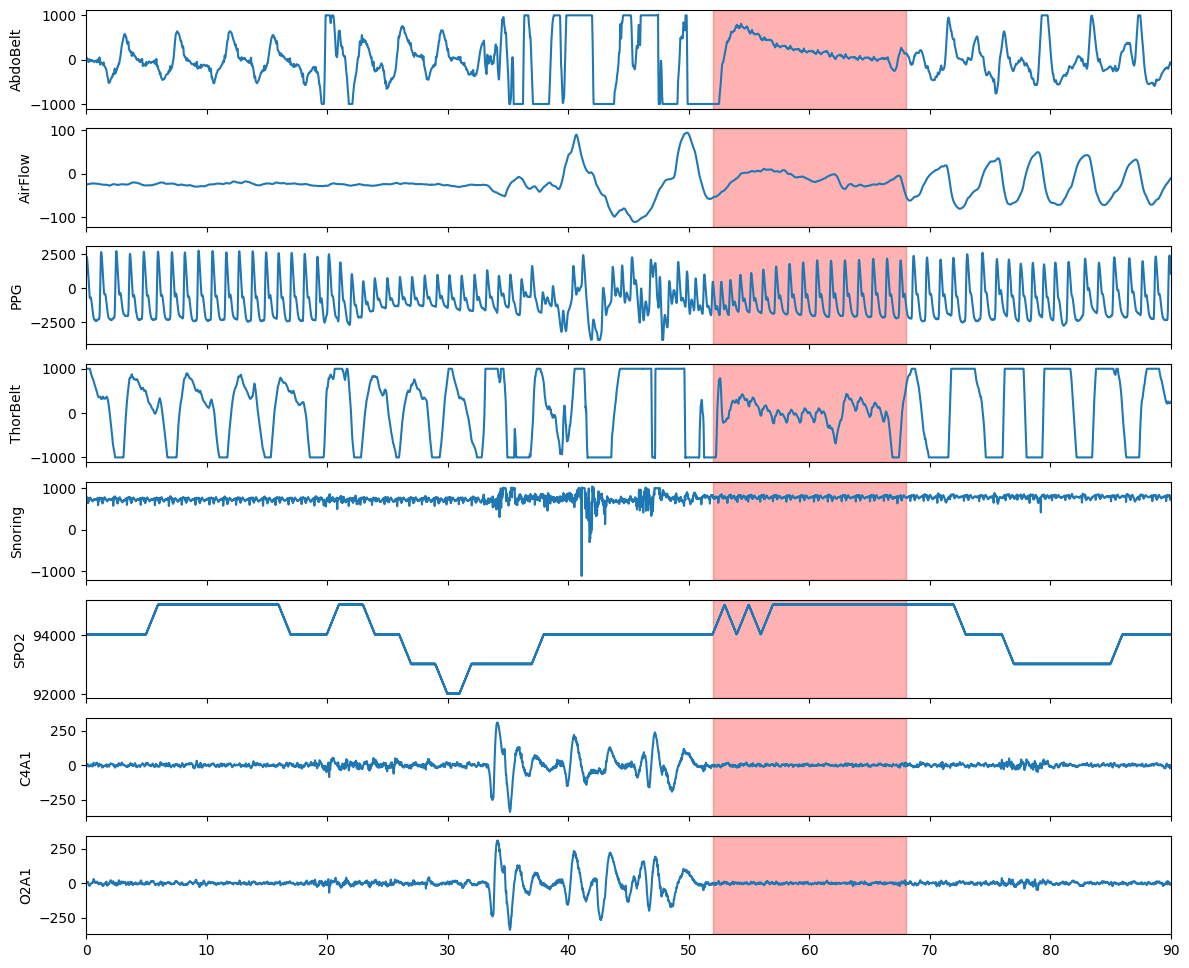

In [49]:
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (14, 12)


h5_file = h5py.File(X_TRAIN_PATH, 'r')
masks = pd.read_csv(Y_TRAIN_PATH).values      # no index_col: visualise_index does masks[idx, 1:]

# 1) Are the two files aligned? Compare ids over the whole set, not just one row
print('same order:', np.array_equal(h5_file['data'][:, 0].astype(int), masks[:, 0].astype(int)))

# 2) Plot a window that has at least one event
has_event = np.where(masks[:, 1:].sum(axis=1) > 0)[0]
print(len(has_event), 'windows with at least one event')
vis.visualise_index(has_event[0], h5_file, masks)

same order: True
900 windows with at least one event


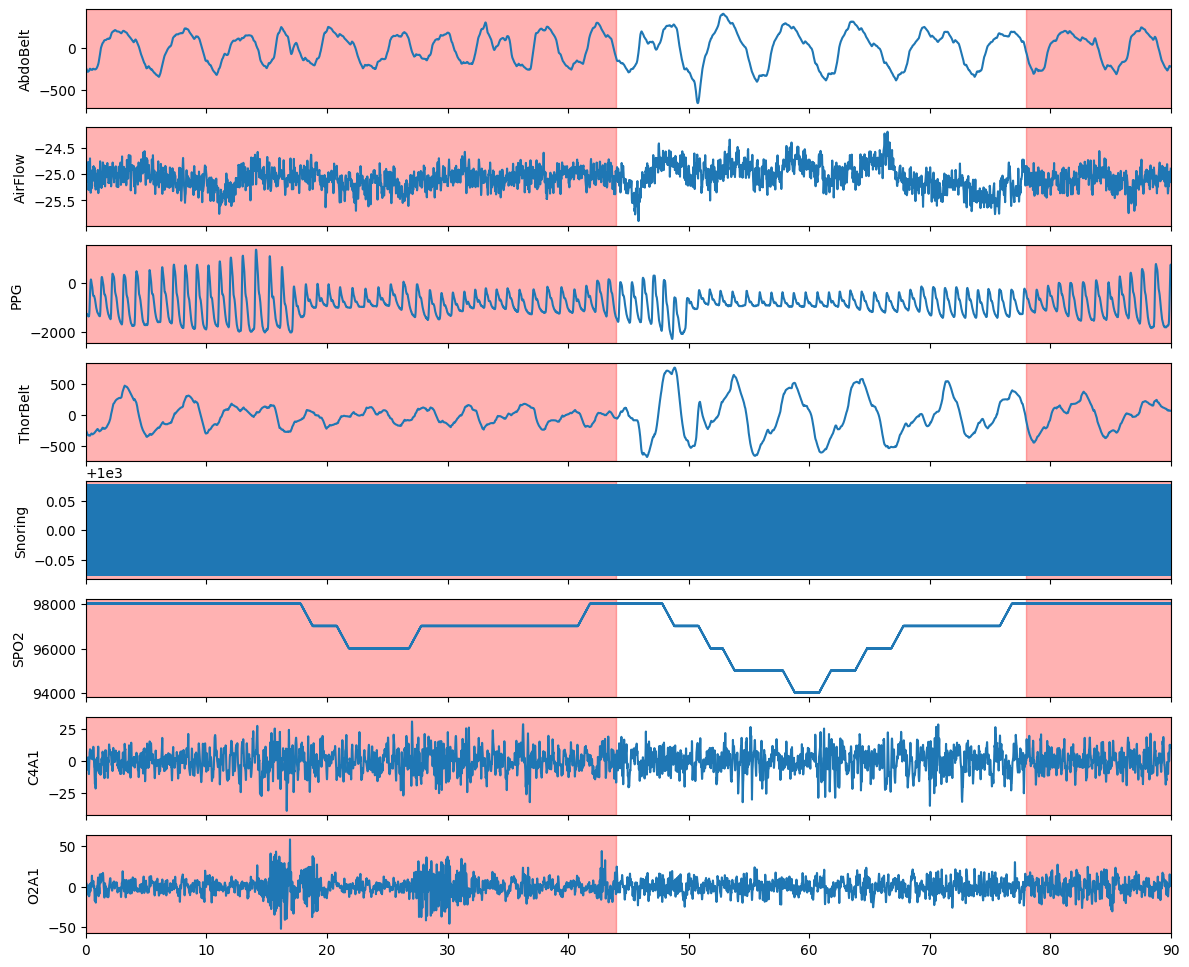

In [50]:
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (14, 12)

h5_file = h5py.File(X_TRAIN_PATH, 'r')
masks = pd.read_csv(Y_TRAIN_PATH).values      # no index_col: visualise_index does masks[idx, 1:]

# 1) Are the two files aligned? Compare ids over the whole set, not just one row
print('same order:', np.array_equal(h5_file['data'][:, 0].astype(int), masks[:, 0].astype(int)))

# 2) Plot a window that has at least one event
has_event = np.where(masks[:, 1:].sum(axis=1) > 0)[0]
print(len(has_event), 'windows with at least one event')
vis.visualise_index(has_event[10], h5_file, masks)

same order: True
900 windows with at least one event


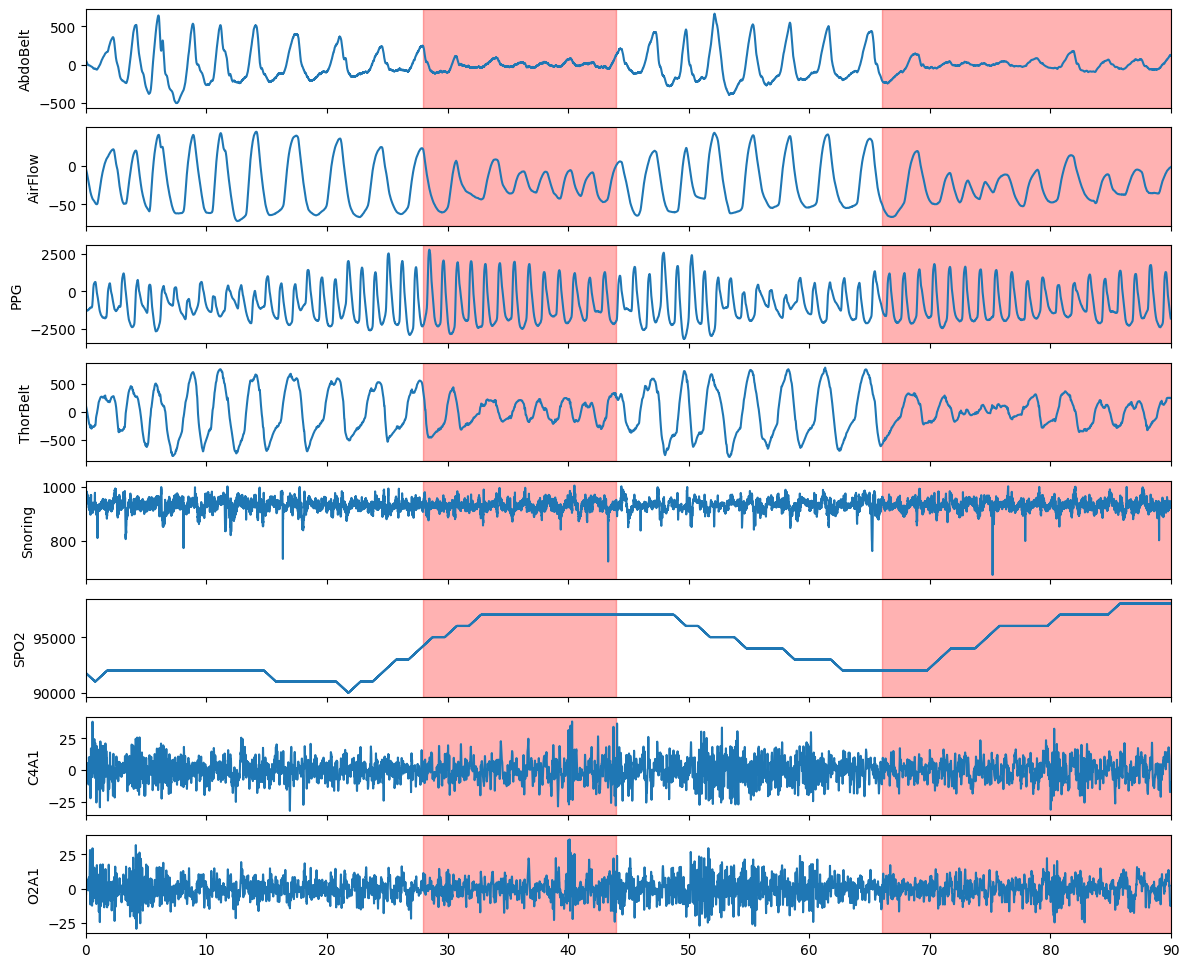

In [51]:
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (14, 12)

h5_file = h5py.File(X_TRAIN_PATH, 'r')
masks = pd.read_csv(Y_TRAIN_PATH).values      # no index_col: visualise_index does masks[idx, 1:]

# 1) Are the two files aligned? Compare ids over the whole set, not just one row
print('same order:', np.array_equal(h5_file['data'][:, 0].astype(int), masks[:, 0].astype(int)))

# 2) Plot a window that has at least one event
has_event = np.where(masks[:, 1:].sum(axis=1) > 0)[0]
print(len(has_event), 'windows with at least one event')
vis.visualise_index(has_event[100], h5_file, masks)